In [1]:
%pip -q install tokenizers gensim scikit-learn matplotlib numpy


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

np.random.seed(0)

In [3]:

BUDOWLA = [
    'Król zbudował zamek na wysokim wzgórzu.',
    'Turyści zwiedzają zamek każdego lata.',
    'Grube mury chronią zamek przed wrogiem.',
    'Wysoka wieża góruje nad okolicą, a zamek widać z daleka.',
    'Rycerze opuścili zamek o świcie.',
    'Zamek stoi nad rzeką od siedmiuset lat.',
    'Król przeniósł swój dwór na zamek w stolicy.',
    'Turyści fotografują zamek z mostu.',
    'Wróg oblegał zamek przez trzy miesiące, ale mury wytrzymały.',
    'Rycerze wrócili na zamek po zwycięskiej bitwie.',
    'Kamienna wieża i zamek zostały odnowione w zeszłym roku.',
    'Przewodnik pokazał turystom zamek i komnaty króla.',
    'Zamek był siedzibą króla przez wiele pokoleń.',
    'Wieża strażnicza pilnowała bramy, a mury otaczały zamek.',
    'Rycerze i giermkowie zamieszkiwali zamek w czasie wojny.',
    'Gotycki zamek przyciąga turystów z całej Europy.',
    'Na dziedzińcu, przez który turyści wchodzą na zamek, trwa turniej.',
    'Król podarował zamek swojemu synowi.',
    'Zamek otoczony fosą był trudny do zdobycia, bo mury były wysokie.',
    'Stara wieża przetrwała pożar, który zniszczył zamek.',
]

MECHANIZM = [
    'Ślusarz wymienił zamek w drzwiach.',
    'Kłódka i zamek zabezpieczają drzwi garażu.',
    'Ślusarz naoliwił zamek, żeby klucz łatwiej się obracał.',
    'Sejf ma solidny zamek i grube ścianki.',
    'Klucz utknął i zamek się zaciął.',
    'Zamek w drzwiach wejściowych otwiera się jednym kluczem.',
    'Ślusarz otworzył zamek bez klucza.',
    'Nowy zamek do drzwi kosztował dwieście złotych.',
    'Ten klucz otwiera zamek w piwnicy.',
    'Złodziej wyłamał zamek w drzwiach balkonowych.',
    'Sejf ma zamek szyfrowy z sześcioma cyframi.',
    'Drzwi biura zamyka elektroniczny zamek.',
    'Klucz złamał się, gdy przekręcałem zamek.',
    'Zamontowaliśmy w drzwiach zamek antywłamaniowy.',
    'Kłódka jest tańsza, ale zamek wpuszczany jest bezpieczniejszy.',
    'Ślusarz rozebrał zamek i wymienił zużytą sprężynę.',
    'Zamek zamarzł w nocy i klucz nie chciał wejść.',
    'Kłódka wisiała na furtce, a zamek w drzwiach był zamknięty.',
    'Mechanik sprawdził zamek w drzwiach samochodu.',
    'Zamek chroni sejf przed niepowołanym otwarciem.',
]

BEZ_ZAMKU = [
    'Ślusarz dorobił klucz do piwnicy.',
    'Zgubiłem klucz i nie mogłem otworzyć drzwi.',
    'Kłódka na rowerze zardzewiała po zimie.',
    'Sejf stał w gabinecie za obrazem.',
    'Ślusarz przyjechał po godzinie i otworzył drzwi.',
    'Kłódka i klucz leżały na półce w garażu.',
    'Król i rycerze ucztowali do rana.',
    'Wieża kościoła była widoczna z rynku, więc turyści szli w jej stronę.',
    'Średniowieczne mury miasta zachowały się do dziś.',
    'Rycerze nosili ciężkie zbroje i miecze.',
    'Król ogłosił turniej, na który przybyli rycerze z całego kraju.',
    'Turyści kupili pamiątki na rynku starego miasta.',
    'Rano piłem kawę i czytałem gazetę.',
    'Pociąg do Krakowa spóźnił się o godzinę.',
    'Na obiad ugotowałam zupę pomidorową.',
    'Dzieci grały w piłkę na boisku za szkołą.',
    'W weekend padał deszcz, więc zostaliśmy w domu.',
    'Kot spał cały dzień na parapecie.',
    'Biblioteka jest otwarta do osiemnastej.',
    'Mój brat uczy się grać na gitarze.',
]


In [4]:
def normalizuj(zdanie):
    """Małe litery, usunięcie interpunkcji, podział na słowa po spacjach."""
    return re.sub(r'[^\w\s]', '', zdanie.lower()).split()


WSZYSTKIE = BUDOWLA + MECHANIZM + BEZ_ZAMKU
for nazwa, pula in [('BUDOWLA', BUDOWLA), ('MECHANIZM', MECHANIZM),
                    ('BEZ_ZAMKU', BEZ_ZAMKU)]:
    ile_zamek = Counter(normalizuj(s).count('zamek') for s in pula)
    print(f'{nazwa:10s} zdań: {len(pula)}  (liczba "zamek" w zdaniu: {dict(ile_zamek)})')

licznik = Counter(w for s in WSZYSTKIE for w in normalizuj(s))
print('Wystąpień słów:', sum(licznik.values()), ' różnych słów:', len(licznik))
print('Formy zaczynające się od "zamk":',
      {w: c for w, c in licznik.items() if w.startswith('zamk')})

BUDOWLA    zdań: 20  (liczba "zamek" w zdaniu: {1: 20})
MECHANIZM  zdań: 20  (liczba "zamek" w zdaniu: {1: 20})
BEZ_ZAMKU  zdań: 20  (liczba "zamek" w zdaniu: {0: 20})
Wystąpień słów: 419  różnych słów: 242
Formy zaczynające się od "zamk": {'zamknięty': 1}


In [5]:
PARY = [('klucz', 'kluczami'), ('wieża', 'wieżami'), ('król', 'królowi'),
        ('drzwi', 'drzwiami'), ('rycerze', 'rycerzom'),
        ('ślusarz', 'ślusarzowi'), ('zamek', 'zamkami'),
        ('turyści', 'turystami')]

for widziana, niewidziana in PARY:
    print(f'{widziana:10s} w korpusie: {licznik[widziana]:2d}   '
          f'{niewidziana:12s} w korpusie: {licznik[niewidziana]}')
assert all(licznik[w] > 0 and licznik[n] == 0 for w, n in PARY)

klucz      w korpusie:  8   kluczami     w korpusie: 0
wieża      w korpusie:  5   wieżami      w korpusie: 0
król       w korpusie:  5   królowi      w korpusie: 0
drzwi      w korpusie:  5   drzwiami     w korpusie: 0
rycerze    w korpusie:  6   rycerzom     w korpusie: 0
ślusarz    w korpusie:  6   ślusarzowi   w korpusie: 0
zamek      w korpusie: 40   zamkami      w korpusie: 0
turyści    w korpusie:  5   turystami    w korpusie: 0


In [6]:
KORPUS_BPE = [' '.join(normalizuj(s)) for s in WSZYSTKIE] 
LIMITY = [100, 300, 1000]


def trenuj_bpe(vocab_size):
    """Trenuje tokenizer BPE na całym korpusie; zmienia się tylko limit."""
    tk = Tokenizer(models.BPE(unk_token='[UNK]'))
    tk.pre_tokenizer = pre_tokenizers.Whitespace()
    tr = trainers.BpeTrainer(vocab_size=vocab_size,
                             special_tokens=['[UNK]'], min_frequency=1)
    tk.train_from_iterator(KORPUS_BPE, tr)
    return tk


tokenizery = {lim: trenuj_bpe(lim) for lim in LIMITY}
widziane = [w for w, _ in PARY]
niewidziane = [n for _, n in PARY]

print(f'{"limit":>6s} {"|V|":>5s} | {"widziane: śr.":>14s} {"[UNK]":>5s} | '
      f'{"niewidziane: śr.":>16s} {"[UNK]":>5s}')
for lim, tk in tokenizery.items():
    wiersz = [lim, tk.get_vocab_size()]
    for grupa in (widziane, niewidziane):
        tokeny = [tk.encode(w).tokens for w in grupa]
        wiersz += [np.mean([len(t) for t in tokeny]),
                   sum('[UNK]' in t for t in tokeny)]
    print(f'{wiersz[0]:6d} {wiersz[1]:5d} | {wiersz[2]:14.2f} {wiersz[3]:5d} | '
          f'{wiersz[4]:16.2f} {wiersz[5]:5d}')










 limit   |V| |  widziane: śr. [UNK] | niewidziane: śr. [UNK]
   100   100 |           1.50     0 |             3.75     0
   300   300 |           1.00     0 |             3.50     0
  1000   739 |           1.00     0 |             3.50     0


In [7]:
for widziana, niewidziana in PARY:
    for forma in (widziana, niewidziana):
        podzialy = [' · '.join(tk.encode(forma).tokens)
                    for tk in tokenizery.values()]
        print(f'{forma:12s}', '  |  '.join(f'{p:22s}' for p in podzialy))

klucz        klucz                   |  klucz                   |  klucz                 
kluczami     klu · c · zam · i       |  klu · c · zam · i       |  klu · c · zam · i     
wieża        wie · ża                |  wieża                   |  wieża                 
wieżami      wie · ż · am · i        |  wie · ż · am · i        |  wie · ż · am · i      
król         król                    |  król                    |  król                  
królowi      król · ow · i           |  król · ow · i           |  król · ow · i         
drzwi        drzwi                   |  drzwi                   |  drzwi                 
drzwiami     drzwi · am · i          |  drzwi · am · i          |  drzwi · am · i        
rycerze      ryce · rze              |  rycerze                 |  rycerze               
rycerzom     ryce · rz · o · m       |  ryce · rz · o · m       |  ryce · rz · o · m     
ślusarz      ślu · sarz              |  ślusarz                 |  ślusarz               
ślusarzowi

In [8]:
for forma in ['ślusarzowi', 'zamkami', 'kluczami']:
    print(f'=== {forma}')
    for lim, tk in tokenizery.items():
        tokeny = tk.encode(forma).tokens
        zrodla = {t: [w for w, _ in licznik.most_common() if t in w][:4]
                  for t in tokeny}
        print(f'  limit {lim}: {" · ".join(tokeny):24s} {zrodla}')

merges = json.loads(tokenizery[300].to_str())['model']['merges']
merges = [' '.join(m) if isinstance(m, list) else m for m in merges]
for para in ['z a', 'za m', 'c z', 'klu cz', 'ślu sarz', 'm i']:
    print(f'reguła {para!r}: pozycja {merges.index(para)}')

=== ślusarzowi
  limit 100: ślu · sarz · ow · i      {'ślu': ['ślusarz'], 'sarz': ['ślusarz'], 'ow': ['zbudował', 'odnowione', 'pilnowała', 'giermkowie'], 'i': ['i', 'się', 'drzwiach', 'turyści']}
  limit 300: ślusarz · ow · i         {'ślusarz': ['ślusarz'], 'ow': ['zbudował', 'odnowione', 'pilnowała', 'giermkowie'], 'i': ['i', 'się', 'drzwiach', 'turyści']}
  limit 1000: ślusarz · ow · i         {'ślusarz': ['ślusarz'], 'ow': ['zbudował', 'odnowione', 'pilnowała', 'giermkowie'], 'i': ['i', 'się', 'drzwiach', 'turyści']}
=== zamkami
  limit 100: zam · ka · m · i         {'zam': ['zamek', 'zamieszkiwali', 'zamyka', 'zamontowaliśmy'], 'ka': ['kłódka', 'każdego', 'wysoka', 'daleka'], 'm': ['zamek', 'mury', 'wymienił', 'ma'], 'i': ['i', 'się', 'drzwiach', 'turyści']}
  limit 300: zam · ka · mi            {'zam': ['zamek', 'zamieszkiwali', 'zamyka', 'zamontowaliśmy'], 'ka': ['kłódka', 'każdego', 'wysoka', 'daleka'], 'mi': ['wymienił', 'miasta', 'siedmiuset', 'miesiące']}
  limit 1000: zam 

In [9]:
WARIANT_1 = BEZ_ZAMKU + BUDOWLA[:12] + MECHANIZM[:4]
WARIANT_2 = BEZ_ZAMKU + BUDOWLA[:4] + MECHANIZM[:12]
POWIELENIE = 5
PARAMS = dict(vector_size=50, window=3, min_count=2, sg=1, epochs=200,
              seed=0, workers=1)


def przygotuj(zdania):
    """Normalizacja i powielenie korpusu (jak w notatniku ćwiczeniowym)."""
    return [normalizuj(s) for s in zdania] * POWIELENIE


dane = {'wariant 1': przygotuj(WARIANT_1), 'wariant 2': przygotuj(WARIANT_2)}
for nazwa, d in dane.items():
    print(nazwa, '- zdań:', len(d), ' wystąpień "zamek":',
          sum(z.count('zamek') for z in d))

w2v = {nazwa: Word2Vec(d, **PARAMS) for nazwa, d in dane.items()}
for nazwa, m in w2v.items():
    print(nazwa, '- słów w modelu:', len(m.wv))

wariant 1 - zdań: 180  wystąpień "zamek": 80
wariant 2 - zdań: 180  wystąpień "zamek": 80
wariant 1 - słów w modelu: 162
wariant 2 - słów w modelu: 151


In [10]:
top5 = {nazwa: m.wv.most_similar('zamek', topn=5) for nazwa, m in w2v.items()}
for nazwa, lista in top5.items():
    print(nazwa, [(w, round(c, 2)) for w, c in lista])


def pozycja(model, slowo):
    """Pozycja słowa w rankingu sąsiadów 'zamek' albo informacja o braku wektora."""
    if slowo not in model.wv:
        return 'brak wektora'
    ranking = [w for w, _ in model.wv.most_similar('zamek', topn=len(model.wv))]
    sim = model.wv.similarity('zamek', slowo)
    return f'pozycja {ranking.index(slowo) + 1}, cos={sim:.2f}'


for skad, dokad in [('wariant 1', 'wariant 2'), ('wariant 2', 'wariant 1')]:
    print(f'--- sąsiedzi z {skad} w modelu {dokad}')
    for w, _ in top5[skad]:
        zdania = [s for s in WSZYSTKIE if w in normalizuj(s)]
        print(f'  {w:12s} {pozycja(w2v[dokad], w):28s} zdania: {zdania[:2]}')

wariant 1 [('mostu', 0.4), ('daleka', 0.39), ('wrogiem', 0.38), ('chronią', 0.37), ('grube', 0.37)]
wariant 2 [('drzwiach', 0.46), ('ślusarz', 0.46), ('grube', 0.45), ('ma', 0.44), ('ścianki', 0.44)]
--- sąsiedzi z wariant 1 w modelu wariant 2
  mostu        brak wektora                 zdania: ['Turyści fotografują zamek z mostu.']
  daleka       pozycja 17, cos=0.40         zdania: ['Wysoka wieża góruje nad okolicą, a zamek widać z daleka.']
  wrogiem      pozycja 7, cos=0.43          zdania: ['Grube mury chronią zamek przed wrogiem.']
  chronią      pozycja 13, cos=0.41         zdania: ['Grube mury chronią zamek przed wrogiem.']
  grube        pozycja 3, cos=0.45          zdania: ['Grube mury chronią zamek przed wrogiem.', 'Sejf ma solidny zamek i grube ścianki.']
--- sąsiedzi z wariant 2 w modelu wariant 1
  drzwiach     pozycja 40, cos=0.30         zdania: ['Ślusarz wymienił zamek w drzwiach.', 'Zamek w drzwiach wejściowych otwiera się jednym kluczem.']
  ślusarz      pozycja 15, 

In [11]:
SLOWA_BUD = {w for s in BUDOWLA + BEZ_ZAMKU[6:12] for w in normalizuj(s)}
SLOWA_MECH = {w for s in MECHANIZM + BEZ_ZAMKU[:6] for w in normalizuj(s)}


def pochodzenie(slowo):
    """Czy słowo występuje tylko w zdaniach o budowli, o mechanizmie, czy w obu."""
    b, m = slowo in SLOWA_BUD, slowo in SLOWA_MECH
    return 'budowla' if b and not m else 'mechanizm' if m and not b else 'inne'


for nazwa, d in dane.items():
    licz = Counter()
    for seed in range(5):
        m = Word2Vec(d, **{**PARAMS, 'seed': seed})
        licz.update(pochodzenie(w) for w, _ in m.wv.most_similar('zamek', topn=5))
    print(nazwa, '- pochodzenie 25 sąsiadów (5 ziaren x top-5):', dict(licz))

wariant 1 - pochodzenie 25 sąsiadów (5 ziaren x top-5): {'budowla': 20, 'inne': 4, 'mechanizm': 1}
wariant 2 - pochodzenie 25 sąsiadów (5 ziaren x top-5): {'mechanizm': 17, 'inne': 4, 'budowla': 4}


Wystąpienia w wariancie 1 (przed powieleniem): {'król': 4, 'wieża': 3, 'mury': 3, 'rycerze': 5, 'turyści': 4, 'klucz': 4, 'drzwi': 3, 'ślusarz': 4, 'kłódka': 3, 'sejf': 2}


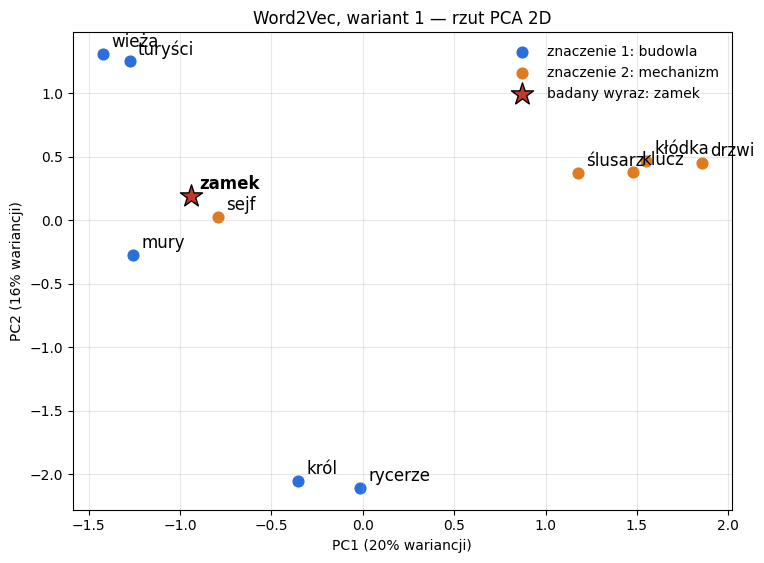

In [12]:
GRUPA_1 = ['król', 'wieża', 'mury', 'rycerze', 'turyści']
GRUPA_2 = ['klucz', 'drzwi', 'ślusarz', 'kłódka', 'sejf']
licz_w1 = Counter(w for s in WARIANT_1 for w in normalizuj(s))
print('Wystąpienia w wariancie 1 (przed powieleniem):',
      {w: licz_w1[w] for w in GRUPA_1 + GRUPA_2})

wv = w2v['wariant 1'].wv
slowa = GRUPA_1 + GRUPA_2 + ['zamek']
pca = PCA(n_components=2, random_state=0)
XY = pca.fit_transform(np.stack([wv[w] for w in slowa]))
ev = pca.explained_variance_ratio_

plt.figure(figsize=(8.5, 6.2))
for grupa, kolor, etykieta in [(GRUPA_1, '#2a6fdb', 'znaczenie 1: budowla'),
                               (GRUPA_2, '#e07a1f', 'znaczenie 2: mechanizm')]:
    idx = [slowa.index(w) for w in grupa]
    plt.scatter(XY[idx, 0], XY[idx, 1], s=60, color=kolor, label=etykieta)
iz = slowa.index('zamek')
plt.scatter(XY[iz, 0], XY[iz, 1], s=280, marker='*', color='#c0392b',
            edgecolor='black', zorder=3, label='badany wyraz: zamek')
for (x, y), w in zip(XY, slowa):
    plt.annotate(w, (x, y), xytext=(6, 5), textcoords='offset points',
                 fontsize=12, fontweight='bold' if w == 'zamek' else 'normal')
plt.xlabel(f'PC1 ({ev[0]:.0%} wariancji)')
plt.ylabel(f'PC2 ({ev[1]:.0%} wariancji)')
plt.title('Word2Vec, wariant 1 — rzut PCA 2D')
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.show()

In [13]:
def sredni_cos(wv, grupa_a, grupa_b=None):
    """Średni cosinus; każda para liczona raz (wewnątrz grupy: bez par (w, w))."""
    if grupa_b is None:
        pary = [(grupa_a[i], grupa_a[j]) for i in range(len(grupa_a))
                for j in range(i + 1, len(grupa_a))]
    else:
        pary = [(a, b) for a in grupa_a for b in grupa_b]
    return np.mean([wv.similarity(a, b) for a, b in pary]), len(pary)


for opis, wynik in [('wewnątrz grupy 1 (budowla)', sredni_cos(wv, GRUPA_1)),
                    ('wewnątrz grupy 2 (mechanizm)', sredni_cos(wv, GRUPA_2)),
                    ('między grupami', sredni_cos(wv, GRUPA_1, GRUPA_2))]:
    print(f'{opis:30s} cos = {wynik[0]:.3f}  (par: {wynik[1]})')

for a, b in [('klucz', 'ślusarz'), ('mury', 'wieża'), ('sejf', 'mury'),
             ('sejf', 'klucz')]:
    print(f'cos({a}, {b}) = {wv.similarity(a, b):.3f}')

wewnątrz grupy 1 (budowla)     cos = 0.243  (par: 10)
wewnątrz grupy 2 (mechanizm)   cos = 0.503  (par: 10)
między grupami                 cos = 0.261  (par: 25)
cos(klucz, ślusarz) = 0.692
cos(mury, wieża) = 0.164
cos(sejf, mury) = 0.386
cos(sejf, klucz) = 0.325
